# Distributional regression: comparison across libraries

This experiment compares Gaussian location-scale regression in mboostrs,
R's gamboostLSS, mssm and NGBoost. Each procedure chooses a configuration
using the same inner folds and predicts a new independent sample. The study
measures predictive distributions and recovery of the known mean and scale
functions, with elapsed analysis costs recorded separately.

The additive track restricts predictors to sums of univariate effects.
The interaction track gives smooth models one declared bilinear interaction
and allows depth-three NGBoost trees. These are comparisons of modeling
procedures: the bases, penalties and interaction restrictions are not identical.
The preceding comparisons cover [](library_comparison.ipynb) and
[](library_comparison_interactions.ipynb).

This advanced benchmark teaches how to compare predictive distributions rather than
point predictions. It shows the recorded protocol first, then reads log score,
calibration, parameter recovery and computation time.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | predictive distribution quality and function recovery under specified learner spaces |
| **Observed response** | a simulated continuous response with Gaussian noise of varying scale |
| **Estimand** | paired differences in external log score, CRPS, and mean/scale recovery between four tuned procedures |
| **Units** | arbitrary response units; log score in natural-log units and CRPS in response units |
| **Sampling unit** | one independent simulated observation |
| **Dependence** | independent rows within each draw; methods share each draw |
| **Split / resampling unit** | independently generated training/test samples, with three inner row folds |
| **Tuning** | three configurations per library selected by pooled inner Gaussian log score |
| **Uncertainty** | Monte Carlo standard errors of paired differences across independent draws |
| **Claim type** | methodological comparison within two known Gaussian generating processes |
:::


## Generating processes

Four independent predictors are uniform on $[-1,1]$. In the additive process,
$\mu=1.5\sin(\pi x_1)+0.6x_2$ and $\log\sigma=-0.4+0.45x_3$.
The interaction process adds $1.2x_1x_2$ to the mean and $0.6x_1x_2$ to log
scale. The fourth predictor is irrelevant in both. In every case
$Y=\mu+\sigma Z$, with $Z\sim N(0,1)$ independent of the predictors.
Every draw has 500 training observations and 2,000 new test observations.

The same covariates are offered to both distribution parameters, so the
procedures do not receive the true division between location and scale.
The interaction pair is prespecified, however; this experiment evaluates
fitting that pair, not discovering it.

## Fitting and configuration selection

| Library | Additive terms | Interaction allowance | Three configurations |
|---|---|---|---|
| mboostrs | P-splines with `df=4`, 10 inner knots | `bols(x1, by=x2, intercept=False)` | 100, 300, 800 cycles, step length 0.05 |
| gamboostLSS | the corresponding R P-splines | the corresponding bilinear term | the same cycles and step length |
| mssm | penalized splines with null-space penalties, smoothing selected by REML | one linear term for `x1*x2` | marginal basis sizes 8, 12, 16 |
| NGBoost | depth-one trees, additive on each parameter's link scale | depth-three trees | 100, 300, 800 rounds, learning rate 0.05 |

Boosting cycle counts and tree round counts do not measure equal amounts of
computation. mssm also estimates smoothing parameters internally. Equal
configuration counts therefore specify this experiment's search effort,
not equal optimizer work or equally generous searches for every library.
Each failed configuration is retained in the artifact; a procedure with no
successful configuration is recorded as failed rather than omitted.

The fitting interfaces are described in the
[gamboostLSS reference](https://search.r-project.org/CRAN/refmans/gamboostLSS/html/mboostLSS.html),
[mssm tutorial](https://jokra1.github.io/mssm/tutorial.html), and
[NGBoost guide](https://stanfordmlgroup.github.io/ngboost/1-useage.html).

## Recorded experiment

`benches/bench_distributional.py` runs the fits and writes
`bench_distributional.json`. The notebook reads that measured output; it does
not fit models from an unexplained JSON specification. The protocol below
shows the data sizes, learner restrictions, configuration grid and selection
rule stored with this run. The artifact is included in the notebook download.

In [1]:
import json
from pathlib import Path

import altair as alt
import numpy as np
import polars as pl
from IPython.display import Markdown, display

# Import the book's plotting style and render charts for both HTML and PDF.
from mboostrs import plot as mbplot

alt.renderers.enable("svg")

RendererRegistry.enable('svg')

In [2]:
# Display the recorded experiment before inspecting its scores.
artifact_path = Path("bench_distributional.json")
document = json.loads(artifact_path.read_text())
protocol = document["protocol"]
display(Markdown("```json\n" + json.dumps(protocol, indent=2) + "\n```"))

# Require every planned combination, including explicitly failed runs.
results = document["results"]
expected_runs = (
    document["repeats"] * len(protocol["scenarios"])
    * len(protocol["tracks"]) * len(protocol["libraries"])
)
run_ids = {(r["scenario"], r["track"], r["library"], r["repeat"]) for r in results}
assert len(run_ids) == len(results) == expected_runs

successful = [result for result in results if result["status"] == "ok"]
failures = [result for result in results if result["status"] != "ok"]
failure_count = len(failures)
display(pl.DataFrame({
    "planned runs": [expected_runs],
    "successful": [len(successful)],
    "failed": [failure_count],
}))
if failures:
    display(pl.DataFrame(failures))

versions = []
for library in protocol["libraries"]:
    package = "ngboost" if library == "NGBoost" else library
    versions.append({"library": library, "version": str(document["versions"].get(package))})
display(pl.DataFrame(versions))

```json
{
  "libraries": [
    "mboostrs",
    "mboostrs + REML refit",
    "mboostrs autospec pairs + REML refit",
    "gamboostLSS",
    "mssm",
    "NGBoost"
  ],
  "family": "Gaussian mean and standard deviation",
  "scenarios": [
    "additive",
    "interaction"
  ],
  "tracks": [
    "additive",
    "supplied",
    "discovery"
  ],
  "train_rows": 500,
  "test_rows": 2000,
  "inner_folds": 3,
  "configurations": 3,
  "boosting_mstop": [
    100,
    300,
    800
  ],
  "learning_rate": 0.05,
  "mssm_basis_sizes": [
    8,
    12,
    16
  ],
  "selection": "lowest pooled inner-fold negative Gaussian log density",
  "basis": "mboostrs/R use bbs; mssm uses REML with null-space penalties; bases and penalties differ",
  "interactions": "additive: none; supplied: the product x1*x2 for every method (a term for smooth models, a column for NGBoost with depth-1 trees); discovery: nothing supplied, NGBoost depth-3 trees, smooth models additive",
  "test_access": "after all configuration choices; no response clipping",
  "warmup": "dependency imports only; no repeated fixed-workload timing or speed ratio",
  "timed_boundary": "all inner fits, final refit, prediction and score calculation"
}
```

planned runs,successful,failed
i64,i64,i64
180,180,0


library,version
str,str
"""mboostrs""","""0.1.3"""
"""mboostrs + REML refit""","""None"""
"""mboostrs autospec pairs + REML…","""None"""
"""gamboostLSS""","""2.2.0"""
"""mssm""","""1.2.5"""
"""NGBoost""","""0.5.11"""


In [3]:
# Expose one complete set of configuration scores and the selected result.
example_result = successful[0]
example_fields = (
    "library", "scenario", "track", "repeat", "seed", "n_train", "n_test",
    "configuration", "inner", "warnings", "metrics", "mean_function_mse", "log_scale_mse", "size",
)
example_record = {field: example_result[field] for field in example_fields}
display(Markdown("```json\n" + json.dumps(example_record, indent=2) + "\n```"))

```json
{
  "library": "mboostrs",
  "scenario": "additive",
  "track": "additive",
  "repeat": 0,
  "seed": 72000,
  "n_train": 500,
  "n_test": 2000,
  "configuration": 1,
  "inner": [
    {
      "configuration": 0,
      "log_score": 1.0279177871315934,
      "errors": []
    },
    {
      "configuration": 1,
      "log_score": 1.0256280050308428,
      "errors": []
    },
    {
      "configuration": 2,
      "log_score": 1.0558578212024001,
      "errors": []
    }
  ],
  "warnings": [],
  "metrics": {
    "log_score": 1.071356365978811,
    "crps": 0.4120024596100404,
    "squared_error": 0.569692177907398,
    "covered_90": 0.8745,
    "width_90": 2.235424648905898
  },
  "mean_function_mse": 0.015277798533814014,
  "log_scale_mse": 0.009274928680343762,
  "size": {
    "selected_components": {
      "mu": 4,
      "sigma": 4
    }
  }
}
```

`configuration` is the zero-based index into the library's three choices.
`inner` records all three held-out log scores and any fitting errors.
`metrics` contains external test scores at the selected configuration.
`mean_function_mse` and `log_scale_mse` compare parameter predictions with
the known generating functions. Model-size fields are library-specific and
are not used as interchangeable measures of effective degrees of freedom.

The mboostrs arm fits the following model in every inner training partition,
changing only `mstop`. The R arm uses the corresponding `bbs` and `bols`
terms. mssm fits the displayed additive structure through its `GAMMLSS`
class; NGBoost uses `NGBRegressor(Dist=Normal, Base=...)` with the tree depth
specified in the protocol. Their full adapters are in the runner.

```python
# All four predictors are offered to both distribution parameters.
formula = "y ~ bbs(x1, df=4, knots=10) + bbs(x2, df=4, knots=10)"
formula += " + bbs(x3, df=4, knots=10) + bbs(noise, df=4, knots=10)"

if track == "interaction":
    formula += " + bols(x1, by=x2, intercept=False)"

fit = mb.gamboostLSS(
    formula, training, family=mb.GaussianLSS(),
    control=mb.boost_control(mstop, 0.05), stabilization="L2",
)
parameters = fit.predict(newdata=validation, type="response")
```

The interaction is bilinear, matching the interaction in the generating
process. A direct LSS formula containing `bbs(x1) %X% bbs(x2)` is not used:
the current LSS formula route does not replay that standard-GAM tensor syntax
correctly. This is a functionality boundary, and the bilinear comparison
does not establish support for smooth LSS tensor surfaces.

In [4]:
# Flatten the scored quantities into rows; retain each independent draw.
rows = []
for result in successful:
    rows.append({
        "library": result["library"],
        "process": result["scenario"],
        "track": result["track"],
        "draw": result["repeat"],
        **result["metrics"],
        "mean function MSE": result["mean_function_mse"],
        "log scale MSE": result["log_scale_mse"],
        "seconds": result["seconds"],
    })
frame = pl.DataFrame(rows)

## Predictive distributions

Negative log score is $\frac12\log(2\pi)+\log\sigma+(y-\mu)^2/(2\sigma^2)$.
The continuous ranked probability score (CRPS) measures the integrated
squared difference between the predictive CDF and the step function at the
observed response. Both are proper scores: their expected value is minimized
by the true predictive distribution. Lower values are better. The runner
checks its Gaussian log score against SciPy's independent `norm.logpdf`.

The table reports means across {eval}`document['repeats']` independent draws
per process and track. There are {eval}`failure_count` failed procedure runs;
any failures are displayed above. Nominal 90% coverage is assessed jointly
with interval width, since wide intervals can cover well without being useful.

In [5]:
# Keep process and learner restrictions separate instead of pooling a rank.
summary = frame.group_by("process", "track", "library").agg(
    pl.len().alias("draws"),
    pl.col("log_score").mean(),
    pl.col("crps").mean(),
    pl.col("covered_90").mean(),
    pl.col("width_90").mean(),
    pl.col("mean function MSE").mean(),
    pl.col("log scale MSE").mean(),
).sort("process", "track", "library")

display(summary.select(
    "process", "track", "library", "draws", "log_score", "crps", "covered_90", "width_90",
))

process,track,library,draws,log_score,crps,covered_90,width_90
str,str,str,u32,f64,f64,f64,f64
"""additive""","""additive""","""NGBoost""",5,1.147188,0.431309,0.864,2.275431
"""additive""","""additive""","""gamboostLSS""",5,1.065113,0.405169,0.8896,2.283764
"""additive""","""additive""","""mboostrs""",5,1.065113,0.405169,0.8896,2.283764
"""additive""","""additive""","""mboostrs + REML refit""",5,1.045632,0.399738,0.8865,2.233776
"""additive""","""additive""","""mboostrs autospec pairs + REML…",5,1.045632,0.399738,0.8865,2.233776
…,…,…,…,…,…,…,…
"""interaction""","""supplied""","""gamboostLSS""",5,1.055447,0.407473,0.8826,2.252884
"""interaction""","""supplied""","""mboostrs""",5,1.055447,0.407473,0.8826,2.252884
"""interaction""","""supplied""","""mboostrs + REML refit""",5,1.043996,0.406262,0.8859,2.262851


The points retain the individual draws. Differences between the additive and
interaction tracks describe different learner spaces as well as their fitting
procedures; the table of paired comparisons below quantifies the differences
within each track.

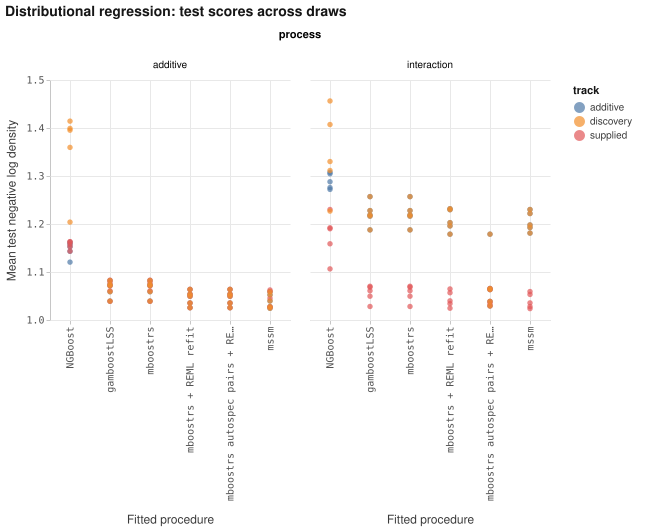

In [6]:
score_chart = alt.Chart(frame).mark_point(filled=True).encode(
    x=alt.X("library:N", title="Fitted procedure"),
    y=alt.Y("log_score:Q", title="Mean test negative log density", scale=alt.Scale(zero=False)),
    color="track:N",
    column="process:N",
    tooltip=["draw", "library", "track", "log_score"],
).properties(title="Distributional regression: test scores across draws", width=240, height=240)
display(score_chart)

## Paired differences and recovery

Pairing within a draw removes the variation caused solely by methods receiving
different data. The following differences are each competitor's log score
minus mboostrs's, with the standard deviation of draw-level differences
divided by the square root of the number of pairs. Positive differences favor
mboostrs. A small Monte Carlo standard error describes repeatability within
these generating processes; it does not establish general superiority.

In [7]:
# Pair only methods evaluated on the same independent training/test draw.
paired = []

for process in protocol["scenarios"]:
    for track in protocol["tracks"]:
        track_rows = [row for row in rows
                      if row["process"] == process and row["track"] == track]
        reference = {row["draw"]: row for row in track_rows if row["library"] == "mboostrs"}

        for library in protocol["libraries"]:
            if library == "mboostrs":
                continue

            differences = []
            for row in track_rows:
                if row["library"] == library and row["draw"] in reference:
                    differences.append(row["log_score"] - reference[row["draw"]]["log_score"])

            delta = np.asarray(differences)
            paired.append({
                "process": process,
                "track": track,
                "competitor": library,
                "paired draws": len(delta),
                "log score difference": float(delta.mean()) if len(delta) else None,
                "Monte Carlo SE": float(delta.std(ddof=1) / np.sqrt(len(delta))) if len(delta) > 1 else None,
            })

display(pl.DataFrame(paired))


process,track,competitor,paired draws,log score difference,Monte Carlo SE
str,str,str,i64,f64,f64
"""additive""","""additive""","""mboostrs + REML refit""",5,-0.01948,0.003807
"""additive""","""additive""","""mboostrs autospec pairs + REML…",5,-0.01948,0.003807
"""additive""","""additive""","""gamboostLSS""",5,7.4163e-14,6.8343e-14
"""additive""","""additive""","""mssm""",5,-0.024544,0.004446
"""additive""","""additive""","""NGBoost""",5,0.082076,0.002041
…,…,…,…,…,…
"""interaction""","""discovery""","""mboostrs + REML refit""",5,-0.013732,0.007412
"""interaction""","""discovery""","""mboostrs autospec pairs + REML…",5,-0.14642,0.035118
"""interaction""","""discovery""","""gamboostLSS""",5,6.6480e-14,6.4552e-14


In [8]:
display(summary.select("process", "track", "library", "mean function MSE", "log scale MSE"))

# Report observed minima without turning them into a significance ranking.

best_rows = summary.sort("log_score").group_by("process", "track", maintain_order=True).first()

sentences = []

for row in best_rows.to_dicts():
    sentences.append(
        f"For the {row['process']} process with the {row['track']} track, {row['library']} "
        f"has the lowest observed mean log score ({row['log_score']:.3f})."
    )

result_sentences = " ".join(sentences)


process,track,library,mean function MSE,log scale MSE
str,str,str,f64,f64
"""additive""","""additive""","""NGBoost""",0.079217,0.026391
"""additive""","""additive""","""gamboostLSS""",0.022776,0.013948
"""additive""","""additive""","""mboostrs""",0.022776,0.013948
"""additive""","""additive""","""mboostrs + REML refit""",0.010862,0.00563
"""additive""","""additive""","""mboostrs autospec pairs + REML…",0.010862,0.00563
…,…,…,…,…
"""interaction""","""supplied""","""gamboostLSS""",0.011726,0.013683
"""interaction""","""supplied""","""mboostrs""",0.011726,0.013683
"""interaction""","""supplied""","""mboostrs + REML refit""",0.010541,0.006308


{eval}`result_sentences` These orderings describe the observed draws; the
paired differences show whether the separations are large relative to their
simulation variability. Mean-function MSE compares predicted location with
the true conditional mean, and log-scale MSE compares predicted log standard
deviation with its true value. A flexible scale fit can partially compensate
for a misspecified mean, so predictive log score and parameter recovery must
be read together.

## Computation and reproducibility

The runner records elapsed time for configuration fitting, final refitting,
prediction and scoring. These costs include different numerical work and
were not measured under an isolated, repeated fixed-workload timing protocol;
the study makes no implementation speed-ratio claim. Thread settings, package
versions, script hashes, source revision, dirty-tree status, input/output
digests and the loaded mboostrs build identity are retained in the artifact.
Peak memory was not measured.

In [9]:
# These are observed workflow costs, not a controlled speed-ratio experiment.
costs = frame.group_by("library", "track").agg(
    pl.col("seconds").median().alias("median workflow seconds"),
    pl.col("seconds").min().alias("minimum seconds"),
    pl.col("seconds").max().alias("maximum seconds"),
).sort("track", "library")
display(costs)

provenance = {field: document[field] for field in
              ("created_at", "commit", "working_tree", "threads", "build_info")}
display(Markdown("```json\n" + json.dumps(provenance, indent=2) + "\n```"))

library,track,median workflow seconds,minimum seconds,maximum seconds
str,str,f64,f64,f64
"""NGBoost""","""additive""",9.65392,8.945783,11.71931
"""gamboostLSS""","""additive""",1.716439,1.629198,1.866997
"""mboostrs""","""additive""",0.098994,0.092267,0.10338
"""mboostrs + REML refit""","""additive""",4.778023,3.879261,5.460136
"""mboostrs autospec pairs + REML…","""additive""",10.219121,6.659963,21.830871
…,…,…,…,…
"""gamboostLSS""","""supplied""",1.921065,1.816828,2.063235
"""mboostrs""","""supplied""",0.097975,0.094358,0.10708
"""mboostrs + REML refit""","""supplied""",4.722428,4.338977,5.768111


```json
{
  "created_at": "2026-10-24T04:09:33+00:00",
  "commit": "f54f1531831e3f14a2db0bd238cf36238683d5ed",
  "working_tree": {
    "dirty": false,
    "status_digest": null,
    "commit_source": "working directory"
  },
  "threads": {
    "logical_cpus": 10,
    "r_mclapply_default_cores": "2",
    "RAYON_NUM_THREADS": null,
    "OMP_NUM_THREADS": null,
    "OPENBLAS_NUM_THREADS": null,
    "MKL_NUM_THREADS": null
  },
  "build_info": {
    "package_version": "0.1.3",
    "source_digest": "sha256:a771766f1a4820a76b9d908fbc12ed53123e648afcb8583181708b5273ca6b49",
    "git_revision": "e9c670d73f2aff2d153b2c02b4cf8a71aa2c46e2",
    "git_dirty": false,
    "rustc": "rustc 1.95.0 (59807616e 2026-04-14) | binary: rustc | commit-hash: 59807616e1fa2540724bfbac14d7976d7e4a3860 | commit-date: 2026-04-14 | host: aarch64-apple-darwin | release: 1.95.0 | LLVM version: 22.1.2",
    "target": "aarch64-apple-darwin",
    "profile": "release",
    "target_features": "aes,crc,dit,dotprod,dpb,dpb2,fcma,fhm,flagm,fp16,frintts,jsconv,lor,lse,neon,paca,pacg,pan,pmuv3,ras,rcpc,rcpc2,rdm,sb,sha2,sha3,ssbs,vh",
    "crate_features": "",
    "abi_version": 1,
    "build_id": "sha256:c54e14030a8b9f4312980db5614bccf5e3fcad401afd2aaecbf7a3812c6e80c9"
  }
}
```

From the repository root, the complete experiment is reproduced by:

```bash
.venv/bin/python -m pip install -r benches/requirements-distributional.txt
RAYON_NUM_THREADS=1 OMP_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1 \
  .venv/bin/python -m benches.bench_distributional --repeats 5
```

R must also provide `mboost` and `gamboostLSS`. The notebook reads the saved
artifact so a normal book build does not require the comparison libraries.

## Scope of the comparison

A successful run means that fitting returned finite parameter predictions and valid scores. The runner retains warnings but does not independently certify convergence of every numerical optimizer.

Two Gaussian processes do not assess skewed or discrete responses, family
selection, group effects, shape constraints, uncertainty after selection, or
large-data performance. The interaction track also gives smooth models the
correct pair in advance while allowing trees other interactions. The number
of draws is small and the configuration grids are deliberately bounded.
This experiment establishes a reproducible comparison within those limits;
it does not establish an overall ranking of libraries.

For a complete application with interpreted units and saved predictions, see
[](munich_rents_distributional.ipynb).